## Stage 1 — Dataset Loading and Structural Inspection

In [2]:
import sys
import pandas as pd
import numpy as np
import matplotlib
import seaborn
import sklearn

print("Python:", sys.executable)
print("All required libraries imported successfully!")

Python: c:\Projects\Python_Practice\.venv\Scripts\python.exe
All required libraries imported successfully!


### 1.1 Library imports and dataset path

In [3]:
from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

pd.set_option("display.max_columns", None)
pd.set_option("display.width", 150)

DATA_DIR = Path(
    r"D:\ML-Project-202618011-And-202618049-\data"
)

print("Libraries imported successfully!")
print("Data folder exists:", DATA_DIR.exists())


Libraries imported successfully!
Data folder exists: True


### 1.2 Dataset file inspection

In [4]:
for file in DATA_DIR.iterdir():
    if file.is_file():
        print(
            f"{file.name} | "
            f"{file.stat().st_size / (1024**2):.2f} MB"
        )


dashboard_clean_15k.csv | 1.83 MB
train_batched.csv | 1373.10 MB
train_cleaned.csv | 1160.93 MB


### 1.3 Load the smaller dataset

In [5]:
file_path = DATA_DIR / "dashboard_clean_15k.csv"

df = pd.read_csv(file_path)

print("Dataset loaded successfully!")
print("Rows:", df.shape[0])
print("Columns:", df.shape[1])
display(df.head())


Dataset loaded successfully!
Rows: 20000
Columns: 21


,city_id,store_id,management_group_id,first_category_id,second_category_id,third_category_id,product_id,dt,sale_amount,discount,holiday_flag,activity_flag,precpt,avg_temperature,avg_humidity,avg_wind_level,total_stockout_hours,total_stock_count,estimated_demand,unit_price_estimate,lost_revenue
0,10,23,6,4,28,142,351,2024-04-18,0.8,1.000,0,0,1.3321,18.70,73.96,1.45,12,4.0,0.7,120,0.0
1,0,189,6,4,28,161,136,2024-05-07,0.5,0.799,0,1,0.7694,21.08,74.25,1.26,0,0.0,0.7,120,24.0
2,13,642,2,31,79,230,530,2024-06-04,0.8,1.000,0,0,6.7654,27.29,84.27,1.77,0,0.0,0.7,120,0.0
3,12,610,6,4,28,167,775,2024-06-20,1.9,0.584,0,1,8.7860,28.28,86.66,1.93,0,0.0,0.7,120,0.0
4,7,824,6,20,50,229,309,2024-04-24,0.2,1.000,0,0,18.1918,24.69,82.06,1.77,14,12.0,0.7,120,60.0


### 1.4 Structural inspection

In [6]:

print("Column names:")
for column in df.columns:
    print(column)

print("\nData types and non-null counts:")
df.info()


Column names:
city_id
store_id
management_group_id
first_category_id
second_category_id
third_category_id
product_id
dt
sale_amount
discount
holiday_flag
activity_flag
precpt
avg_temperature
avg_humidity
avg_wind_level
total_stockout_hours
total_stock_count
estimated_demand
unit_price_estimate
lost_revenue

Data types and non-null counts:
<class 'pandas.DataFrame'>
RangeIndex: 20000 entries, 0 to 19999
Data columns (total 21 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   city_id               20000 non-null  int64  
 1   store_id              20000 non-null  int64  
 2   management_group_id   20000 non-null  int64  
 3   first_category_id     20000 non-null  int64  
 4   second_category_id    20000 non-null  int64  
 5   third_category_id     20000 non-null  int64  
 6   product_id            20000 non-null  int64  
 7   dt                    20000 non-null  str    
 8   sale_amount           20000 non-null  float64


## Stage 2 — Data Quality Assessment

### 2.1 Initial data quality report

In [7]:
quality_report = pd.DataFrame({
    "Data_Type": df.dtypes.astype(str),
    "Missing_Count": df.isnull().sum(),
    "Missing_Percentage": (df.isnull().mean() * 100).round(2),
    "Unique_Values": df.nunique()
})

display(quality_report)
print("Duplicate rows:", df.duplicated().sum())


,Data_Type,Missing_Count,Missing_Percentage,Unique_Values
city_id,int64,0,0.0,18
store_id,int64,0,0.0,897
management_group_id,int64,0,0.0,7
first_category_id,int64,0,0.0,32
second_category_id,int64,0,0.0,78
third_category_id,int64,0,0.0,209
product_id,int64,0,0.0,696
dt,str,0,0.0,90
sale_amount,float64,0,0.0,135
discount,float64,0,0.0,741


Duplicate rows: 0


### 2.2 Preview the large training dataset

In [8]:
large_file = DATA_DIR / "train_batched.csv"

# Read only five rows, with the Python CSV parser
preview = pd.read_csv(
    large_file,
    nrows=5,
    engine="python",
    on_bad_lines="warn"
)

print("Columns:", preview.columns.tolist())
print("Preview shape:", preview.shape)
display(preview)


Columns: ['city_id', 'store_id', 'management_group_id', 'first_category_id', 'second_category_id', 'third_category_id', 'product_id', 'dt', 'sale_amount', 'hours_sale', 'stock_hour6_22_cnt', 'hours_stock_status', 'discount', 'holiday_flag', 'activity_flag', 'precpt', 'avg_temperature', 'avg_humidity', 'avg_wind_level']
Preview shape: (5, 19)


,city_id,store_id,management_group_id,first_category_id,second_category_id,third_category_id,product_id,dt,sale_amount,hours_sale,stock_hour6_22_cnt,hours_stock_status,discount,holiday_flag,activity_flag,precpt,avg_temperature,avg_humidity,avg_wind_level
0,0,0,0,5,6,65,38,2024-03-28,0.1,"[0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.1, 0.0, ...",0,"[0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, ...",1.0,0,0,1.6999,15.48,73.54,1.97
1,0,0,0,5,6,65,38,2024-03-29,0.1,"[0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.1, 0.0, 0.0, ...",1,"[0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, ...",1.0,0,0,3.0190,15.08,76.56,1.71
2,0,0,0,5,6,65,38,2024-03-30,0.0,"[0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, ...",0,"[1, 1, 1, 1, 1, 1, 0, 0, 0, 0, 0, 0, 0, 0, 0, ...",1.0,1,0,2.0942,15.91,76.47,1.73
3,0,0,0,5,6,65,38,2024-03-31,0.1,"[0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.1, ...",11,"[0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 1, 1, 1, 1, ...",1.0,1,0,1.5618,16.13,77.40,1.76
4,0,0,0,5,6,65,38,2024-04-01,0.2,"[0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.1, 0.0, 0.0, ...",8,"[1, 1, 1, 1, 1, 0, 0, 0, 0, 0, 0, 0, 0, 0, 1, ...",1.0,0,0,3.5386,15.37,78.26,1.25


### 2.3 Full Dataset Quality Assessment

In [9]:
large_file = DATA_DIR / "train_batched.csv"

chunk_size = 200_000
total_rows = 0
missing_counts = None
invalid_date_count = 0
date_min = None
date_max = None

numeric_columns = [
    "sale_amount",
    "discount",
    "precpt",
    "avg_temperature",
    "avg_humidity",
    "avg_wind_level"
]

numeric_stats = {}

for chunk in pd.read_csv(large_file, chunksize=chunk_size):

    total_rows += len(chunk)

    # Missing values
    chunk_missing = chunk.isna().sum()

    if missing_counts is None:
        missing_counts = chunk_missing
    else:
        missing_counts += chunk_missing

    # Date validation
    dates = pd.to_datetime(chunk["dt"], errors="coerce")
    invalid_date_count += dates.isna().sum()

    valid_dates = dates.dropna()

    if not valid_dates.empty:
        chunk_min = valid_dates.min()
        chunk_max = valid_dates.max()

        date_min = chunk_min if date_min is None else min(date_min, chunk_min)
        date_max = chunk_max if date_max is None else max(date_max, chunk_max)

    # Numerical ranges
    for col in numeric_columns:
        values = pd.to_numeric(chunk[col], errors="coerce").dropna()

        if not values.empty:
            if col not in numeric_stats:
                numeric_stats[col] = {
                    "Minimum": values.min(),
                    "Maximum": values.max()
                }
            else:
                numeric_stats[col]["Minimum"] = min(
                    numeric_stats[col]["Minimum"], values.min()
                )
                numeric_stats[col]["Maximum"] = max(
                    numeric_stats[col]["Maximum"], values.max()
                )

print("Total rows:", total_rows)
print("Invalid dates:", invalid_date_count)
print("Date range:", date_min, "to", date_max)

missing_report = pd.DataFrame({
    "Missing_Count": missing_counts,
    "Missing_Percentage": (
        missing_counts / total_rows * 100
    ).round(2)
})

print("\nMissing Value Report")
display(missing_report)

print("\nNumerical Feature Ranges")
display(pd.DataFrame(numeric_stats).T)


C:\Users\Diya\AppData\Local\Temp\ipykernel_43192\656506616.py:21: DtypeWarning: Columns (0: city_id, 1: store_id, 2: management_group_id, 3: first_category_id, 4: second_category_id, 5: third_category_id, 6: product_id, 7: sale_amount, 8: stock_hour6_22_cnt, 9: discount, 10: holiday_flag, 11: activity_flag, 12: precpt, 13: avg_temperature, 14: avg_humidity, 15: avg_wind_level) have mixed types. Specify dtype option on import or set low_memory=False.
  for chunk in pd.read_csv(large_file, chunksize=chunk_size):
C:\Users\Diya\AppData\Local\Temp\ipykernel_43192\656506616.py:21: DtypeWarning: Columns (0: city_id, 1: store_id, 2: management_group_id, 3: first_category_id, 4: second_category_id, 5: third_category_id, 6: product_id, 7: sale_amount, 8: stock_hour6_22_cnt, 9: discount, 10: holiday_flag, 11: activity_flag, 12: precpt, 13: avg_temperature, 14: avg_humidity, 15: avg_wind_level) have mixed types. Specify dtype option on import or set low_memory=False.
  for chunk in pd.read_csv(lar

Total rows: 5325002
Invalid dates: 2
Date range: 2024-03-28 00:00:00 to 2024-06-25 00:00:00

Missing Value Report


,Missing_Count,Missing_Percentage
city_id,0,0.0
store_id,0,0.0
management_group_id,0,0.0
first_category_id,0,0.0
second_category_id,0,0.0
third_category_id,0,0.0
product_id,0,0.0
dt,0,0.0
sale_amount,0,0.0
hours_sale,0,0.0



Numerical Feature Ranges


,Minimum,Maximum
sale_amount,0.00,44.900
discount,0.00,1.088
precpt,0.00,42.500
avg_temperature,12.06,30.880
avg_humidity,27.35,100.000
avg_wind_level,0.97,3.850


### 2.4 Duplicate and Validity Checks

In [10]:
import sqlite3
import tempfile
from pathlib import Path

chunk_size = 200_000

total_rows = 0
unique_dates = set()
duplicate_keys = 0

checks = {
    "negative_sale_amount": 0,
    "negative_discount": 0,
    "discount_above_1": 0,
    "negative_precpt": 0,
    "invalid_holiday_flag": 0,
    "invalid_activity_flag": 0
}

with tempfile.TemporaryDirectory() as temp_dir:
    db_path = Path(temp_dir) / "duplicate_check.db"
    conn = sqlite3.connect(db_path)

    conn.execute("""
        CREATE TABLE records (
            store_id TEXT,
            product_id TEXT,
            dt TEXT,
            PRIMARY KEY (store_id, product_id, dt)
        )
    """)

    for chunk in pd.read_csv(large_file, chunksize=chunk_size):
        total_rows += len(chunk)

        # Check unique dates
        unique_dates.update(chunk["dt"].dropna().astype(str).unique())

        # Check duplicate store-product-date combinations
        records = (
            chunk[["store_id", "product_id", "dt"]]
            .astype(str)
            .itertuples(index=False, name=None)
        )

        before = conn.total_changes
        conn.executemany(
            "INSERT OR IGNORE INTO records VALUES (?, ?, ?)",
            records
        )
        inserted = conn.total_changes - before
        duplicate_keys += len(chunk) - inserted

        # Check unusual values
        checks["negative_sale_amount"] += (
            pd.to_numeric(chunk["sale_amount"], errors="coerce") < 0
        ).sum()

        discount = pd.to_numeric(chunk["discount"], errors="coerce")
        checks["negative_discount"] += (discount < 0).sum()
        checks["discount_above_1"] += (discount > 1).sum()

        checks["negative_precpt"] += (
            pd.to_numeric(chunk["precpt"], errors="coerce") < 0
        ).sum()

        checks["invalid_holiday_flag"] += (
            ~chunk["holiday_flag"].isin([0, 1])
        ).sum()

        checks["invalid_activity_flag"] += (
            ~chunk["activity_flag"].isin([0, 1])
        ).sum()

    conn.close()

print("Total rows checked:", total_rows)
print("Unique dates:", len(unique_dates))
print("Duplicate store-product-date records:", duplicate_keys)

print("\nValue validation results:")
display(pd.Series(checks, name="Count").to_frame())


C:\Users\Diya\AppData\Local\Temp\ipykernel_43192\2348874935.py:33: DtypeWarning: Columns (0: city_id, 1: store_id, 2: management_group_id, 3: first_category_id, 4: second_category_id, 5: third_category_id, 6: product_id, 7: sale_amount, 8: stock_hour6_22_cnt, 9: discount, 10: holiday_flag, 11: activity_flag, 12: precpt, 13: avg_temperature, 14: avg_humidity, 15: avg_wind_level) have mixed types. Specify dtype option on import or set low_memory=False.
  for chunk in pd.read_csv(large_file, chunksize=chunk_size):
C:\Users\Diya\AppData\Local\Temp\ipykernel_43192\2348874935.py:33: DtypeWarning: Columns (0: city_id, 1: store_id, 2: management_group_id, 3: first_category_id, 4: second_category_id, 5: third_category_id, 6: product_id, 7: sale_amount, 8: stock_hour6_22_cnt, 9: discount, 10: holiday_flag, 11: activity_flag, 12: precpt, 13: avg_temperature, 14: avg_humidity, 15: avg_wind_level) have mixed types. Specify dtype option on import or set low_memory=False.
  for chunk in pd.read_csv(l

Total rows checked: 5325002
Unique dates: 91
Duplicate store-product-date records: 825001

Value validation results:


,Count
negative_sale_amount,0
negative_discount,0
discount_above_1,34
negative_precpt,0
invalid_holiday_flag,65536
invalid_activity_flag,65536


### 2.5 Investigation of Data Anomalies

In [11]:
from collections import Counter

flag_values = {
    "holiday_flag": Counter(),
    "activity_flag": Counter()
}

discount_values = Counter()
invalid_date_values = Counter()
valid_date_count = 0

for chunk in pd.read_csv(large_file, chunksize=200_000):

    # Inspect actual flag values
    for col in flag_values:
        values = chunk[col].astype("string").fillna("<MISSING>")
        flag_values[col].update(values.value_counts().to_dict())

    # Inspect discounts above 1
    discount = pd.to_numeric(chunk["discount"], errors="coerce")
    discount_values.update(
        discount[discount > 1].value_counts().to_dict()
    )

    # Recheck dates
    dates = pd.to_datetime(chunk["dt"], errors="coerce")
    valid_date_count += dates.notna().sum()

    invalid_values = chunk.loc[dates.isna(), "dt"].astype(str)
    invalid_date_values.update(invalid_values.value_counts().to_dict())

print("Holiday flag values:")
print(flag_values["holiday_flag"])

print("\nActivity flag values:")
print(flag_values["activity_flag"])

print("\nDiscount values above 1:")
print(discount_values)

print("\nValid date records:", valid_date_count)
print("Invalid date values:", invalid_date_values)


C:\Users\Diya\AppData\Local\Temp\ipykernel_43192\1371616643.py:12: DtypeWarning: Columns (0: city_id, 1: store_id, 2: management_group_id, 3: first_category_id, 4: second_category_id, 5: third_category_id, 6: product_id, 7: sale_amount, 8: stock_hour6_22_cnt, 9: discount, 10: holiday_flag, 11: activity_flag, 12: precpt, 13: avg_temperature, 14: avg_humidity, 15: avg_wind_level) have mixed types. Specify dtype option on import or set low_memory=False.
  for chunk in pd.read_csv(large_file, chunksize=200_000):
C:\Users\Diya\AppData\Local\Temp\ipykernel_43192\1371616643.py:12: DtypeWarning: Columns (0: city_id, 1: store_id, 2: management_group_id, 3: first_category_id, 4: second_category_id, 5: third_category_id, 6: product_id, 7: sale_amount, 8: stock_hour6_22_cnt, 9: discount, 10: holiday_flag, 11: activity_flag, 12: precpt, 13: avg_temperature, 14: avg_humidity, 15: avg_wind_level) have mixed types. Specify dtype option on import or set low_memory=False.
  for chunk in pd.read_csv(larg

Holiday flag values:
Counter({'0': 3490831, '1': 1834169, 'holiday_flag': 2})

Activity flag values:
Counter({'0': 3286660, '1': 2038340, 'activity_flag': 2})

Discount values above 1:
Counter({1.088: 18, 1.059: 4, 1.07: 3, 1.05: 2, 1.042: 1, 1.019: 1, 1.033: 1, 1.044: 1, 1.043: 1, 1.065: 1, 1.02: 1})

Valid date records: 5325000
Invalid date values: Counter({'dt': 2})


In [12]:
sample_size = 10
duplicate_samples = []
seen_keys = set()

for chunk in pd.read_csv(large_file, chunksize=200_000):

    keys = chunk[["store_id", "product_id", "dt"]].astype(str)

    for idx, key in keys.iterrows():
        key_tuple = tuple(key)

        if key_tuple in seen_keys:
            if len(duplicate_samples) < sample_size:
                duplicate_samples.append(chunk.loc[idx].to_dict())
        else:
            seen_keys.add(key_tuple)

        if len(duplicate_samples) >= sample_size:
            break

    if len(duplicate_samples) >= sample_size:
        break

if duplicate_samples:
    display(pd.DataFrame(duplicate_samples))
else:
    print("No duplicate examples found.")


C:\Users\Diya\AppData\Local\Temp\ipykernel_43192\831330079.py:5: DtypeWarning: Columns (0: city_id, 1: store_id, 2: management_group_id, 3: first_category_id, 4: second_category_id, 5: third_category_id, 6: product_id, 7: sale_amount, 8: stock_hour6_22_cnt, 9: discount, 10: holiday_flag, 11: activity_flag, 12: precpt, 13: avg_temperature, 14: avg_humidity, 15: avg_wind_level) have mixed types. Specify dtype option on import or set low_memory=False.
  for chunk in pd.read_csv(large_file, chunksize=200_000):


,city_id,store_id,management_group_id,first_category_id,second_category_id,third_category_id,product_id,dt,sale_amount,hours_sale,stock_hour6_22_cnt,hours_stock_status,discount,holiday_flag,activity_flag,precpt,avg_temperature,avg_humidity,avg_wind_level
0,0,0,0,5,6,65,38,2024-03-28,0.1,"[0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.1, 0.0, ...",0,"[0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, ...",1.0,0,0,1.6999,15.48,73.54,1.97
1,0,0,0,5,6,65,38,2024-03-29,0.1,"[0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.1, 0.0, 0.0, ...",1,"[0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, ...",1.0,0,0,3.019,15.08,76.56,1.71
2,0,0,0,5,6,65,38,2024-03-30,0.0,"[0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, ...",0,"[1, 1, 1, 1, 1, 1, 0, 0, 0, 0, 0, 0, 0, 0, 0, ...",1.0,1,0,2.0942,15.91,76.47,1.73
3,0,0,0,5,6,65,38,2024-03-31,0.1,"[0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.1, ...",11,"[0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 1, 1, 1, 1, ...",1.0,1,0,1.5618,16.13,77.4,1.76
4,0,0,0,5,6,65,38,2024-04-01,0.2,"[0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.1, 0.0, 0.0, ...",8,"[1, 1, 1, 1, 1, 0, 0, 0, 0, 0, 0, 0, 0, 0, 1, ...",1.0,0,0,3.5386,15.37,78.26,1.25
5,0,0,0,5,6,65,38,2024-04-02,0.1,"[0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.1, 0.0, ...",0,"[1, 1, 1, 1, 1, 1, 0, 0, 0, 0, 0, 0, 0, 0, 0, ...",1.0,0,0,3.1459,15.69,76.63,2.13
6,0,0,0,5,6,65,38,2024-04-03,0.1,"[0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, ...",0,"[0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, ...",1.0,0,0,1.7165,16.11,76.31,1.51
7,0,0,0,5,6,65,38,2024-04-04,0.2,"[0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, ...",0,"[0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, ...",1.0,1,0,1.3021,16.08,74.24,1.47
8,0,0,0,5,6,65,38,2024-04-05,0.0,"[0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, ...",0,"[0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, ...",1.0,1,0,1.909,16.24,71.99,1.46
9,0,0,0,5,6,65,38,2024-04-06,0.2,"[0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, ...",0,"[0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, ...",1.0,1,0,2.4001,16.72,78.42,1.67


### 2.6 Final Duplicate and Header Validation

In [13]:
import sqlite3
import tempfile
from pathlib import Path

chunk_size = 200_000

total_valid_rows = 0
repeated_headers = 0
duplicate_full_rows = 0
duplicate_keys = 0

with tempfile.TemporaryDirectory() as temp_dir:
    conn = sqlite3.connect(Path(temp_dir) / "validation.db")

    conn.execute("""
        CREATE TABLE records (
            row_hash TEXT PRIMARY KEY
        )
    """)

    conn.execute("""
        CREATE TABLE store_product_dates (
            store_id TEXT,
            product_id TEXT,
            dt TEXT,
            PRIMARY KEY (store_id, product_id, dt)
        )
    """)

    for chunk in pd.read_csv(
        large_file,
        chunksize=chunk_size,
        dtype=str
    ):
        # Remove repeated header rows
        header_mask = (
            chunk["dt"].eq("dt") |
            chunk["store_id"].eq("store_id") |
            chunk["product_id"].eq("product_id")
        )

        repeated_headers += int(header_mask.sum())
        chunk = chunk.loc[~header_mask].copy()

        total_valid_rows += len(chunk)

        # Check identical complete rows
        row_hashes = pd.util.hash_pandas_object(
            chunk, index=False
        ).astype(str)

        before = conn.total_changes
        conn.executemany(
            "INSERT OR IGNORE INTO records VALUES (?)",
            ((h,) for h in row_hashes)
        )
        duplicate_full_rows += len(chunk) - (
            conn.total_changes - before
        )

        # Check repeated store-product-date keys
        keys = chunk[["store_id", "product_id", "dt"]]

        before = conn.total_changes
        conn.executemany(
            "INSERT OR IGNORE INTO store_product_dates VALUES (?, ?, ?)",
            keys.itertuples(index=False, name=None)
        )
        duplicate_keys += len(chunk) - (
            conn.total_changes - before
        )

    conn.close()

print("Valid data rows:", total_valid_rows)
print("Repeated header rows:", repeated_headers)
print("Identical full duplicate rows:", duplicate_full_rows)
print("Repeated store-product-date keys:", duplicate_keys)


Valid data rows: 5325000
Repeated header rows: 2
Identical full duplicate rows: 825000
Repeated store-product-date keys: 825000


## 3. Data Cleaning and Preprocessing

### 3.1 Data Cleaning

In [14]:
cleaned_file = DATA_DIR / "train_cleaned.csv"

chunk_size = 200_000
first_chunk = True

total_input_rows = 0
removed_headers = 0
removed_duplicates = 0
total_output_rows = 0

# Temporary database for tracking duplicate records
import sqlite3
import tempfile

with tempfile.TemporaryDirectory() as temp_dir:
    conn = sqlite3.connect(
        Path(temp_dir) / "cleaning.db"
    )

    conn.execute("""
        CREATE TABLE seen_rows (
            row_hash TEXT PRIMARY KEY
        )
    """)

    if cleaned_file.exists():
        cleaned_file.unlink()

    for chunk in pd.read_csv(
        large_file,
        chunksize=chunk_size,
        dtype=str
    ):

        total_input_rows += len(chunk)

        # Remove repeated CSV headers
        header_mask = (
            chunk["dt"].eq("dt") |
            chunk["store_id"].eq("store_id") |
            chunk["product_id"].eq("product_id")
        )

        removed_headers += int(header_mask.sum())
        chunk = chunk.loc[~header_mask].copy()

        # Remove exact duplicate rows
        hashes = pd.util.hash_pandas_object(
            chunk, index=False
        ).astype(str)

        keep_mask = []

        for row_hash in hashes:
            before = conn.total_changes

            conn.execute(
                "INSERT OR IGNORE INTO seen_rows VALUES (?)",
                (row_hash,)
            )

            keep_mask.append(
                conn.total_changes > before
            )

        keep_mask = np.array(keep_mask, dtype=bool)

        removed_duplicates += int((~keep_mask).sum())
        chunk = chunk.loc[keep_mask].copy()

        total_output_rows += len(chunk)

        # Append cleaned chunk to output CSV
        chunk.to_csv(
            cleaned_file,
            mode="w" if first_chunk else "a",
            header=first_chunk,
            index=False
        )

        first_chunk = False

    conn.close()

print("Cleaning completed!")

print("Original rows:", total_input_rows)
print("Repeated headers removed:", removed_headers)
print("Duplicate rows removed:", removed_duplicates)
print("Final cleaned rows:", total_output_rows)
print("Cleaned file:", cleaned_file)


Cleaning completed!
Original rows: 5325002
Repeated headers removed: 2
Duplicate rows removed: 825000
Final cleaned rows: 4500000
Cleaned file: D:\ML-Project-202618011-And-202618049-\data\train_cleaned.csv


### 3.2 Cleaned Dataset Verification

In [15]:
cleaned_df = pd.read_csv(
    cleaned_file,
    nrows=5
)

print("Cleaned dataset preview:")
display(cleaned_df)

print("\nColumn names:")
print(cleaned_df.columns.tolist())

# Verify row count and duplicate count in chunks
verified_rows = 0
remaining_duplicates = 0
seen_hashes = set()

for chunk in pd.read_csv(
    cleaned_file,
    chunksize=200_000
):
    verified_rows += len(chunk)

    hashes = pd.util.hash_pandas_object(
        chunk, index=False
    )

    remaining_duplicates += hashes.duplicated().sum()

    # Cross-chunk duplicate verification
    for h in hashes:
        if h in seen_hashes:
            remaining_duplicates += 1
        else:
            seen_hashes.add(h)

print("\nVerified row count:", verified_rows)
print("Remaining exact duplicates:", remaining_duplicates)
print("Cleaned file size (MB):",
    round(cleaned_file.stat().st_size / (1024**2), 2))


Cleaned dataset preview:


,city_id,store_id,management_group_id,first_category_id,second_category_id,third_category_id,product_id,dt,sale_amount,hours_sale,stock_hour6_22_cnt,hours_stock_status,discount,holiday_flag,activity_flag,precpt,avg_temperature,avg_humidity,avg_wind_level
0,0,0,0,5,6,65,38,2024-03-28,0.1,"[0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.1, 0.0, ...",0,"[0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, ...",1.0,0,0,1.6999,15.48,73.54,1.97
1,0,0,0,5,6,65,38,2024-03-29,0.1,"[0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.1, 0.0, 0.0, ...",1,"[0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, ...",1.0,0,0,3.0190,15.08,76.56,1.71
2,0,0,0,5,6,65,38,2024-03-30,0.0,"[0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, ...",0,"[1, 1, 1, 1, 1, 1, 0, 0, 0, 0, 0, 0, 0, 0, 0, ...",1.0,1,0,2.0942,15.91,76.47,1.73
3,0,0,0,5,6,65,38,2024-03-31,0.1,"[0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.1, ...",11,"[0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 1, 1, 1, 1, ...",1.0,1,0,1.5618,16.13,77.40,1.76
4,0,0,0,5,6,65,38,2024-04-01,0.2,"[0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.1, 0.0, 0.0, ...",8,"[1, 1, 1, 1, 1, 0, 0, 0, 0, 0, 0, 0, 0, 0, 1, ...",1.0,0,0,3.5386,15.37,78.26,1.25



Column names:
['city_id', 'store_id', 'management_group_id', 'first_category_id', 'second_category_id', 'third_category_id', 'product_id', 'dt', 'sale_amount', 'hours_sale', 'stock_hour6_22_cnt', 'hours_stock_status', 'discount', 'holiday_flag', 'activity_flag', 'precpt', 'avg_temperature', 'avg_humidity', 'avg_wind_level']

Verified row count: 4500000
Remaining exact duplicates: 0
Cleaned file size (MB): 1160.93


### 3.2 Cleaned Dataset Verification.

In [16]:
total_rows = 0
missing_counts = None
first_date = None
last_date = None

for chunk in pd.read_csv(cleaned_file, chunksize=200_000):

    total_rows += len(chunk)

    chunk_missing = chunk.isnull().sum()

    if missing_counts is None:
        missing_counts = chunk_missing
    else:
        missing_counts += chunk_missing

    dates = pd.to_datetime(chunk["dt"], errors="coerce").dropna()

    if not dates.empty:
        first_date = dates.min() if first_date is None else min(first_date, dates.min())
        last_date = dates.max() if last_date is None else max(last_date, dates.max())

print("Total cleaned rows:", total_rows)
print("\nMissing values:")
display(missing_counts[missing_counts > 0])

print("\nDate range:", first_date, "to", last_date)
print("\nCleaned file size (MB):",
    round(cleaned_file.stat().st_size / (1024**2), 2))


Total cleaned rows: 4500000

Missing values:


Series([], dtype: int64)


Date range: 2024-03-28 00:00:00 to 2024-06-25 00:00:00

Cleaned file size (MB): 1160.93


### 3.3 Data Type Conversion

In [17]:
# Load a small sample to inspect the current data types
sample_df = pd.read_csv(cleaned_file, nrows=5)

print("Current data types:")
print(sample_df.dtypes)

print("\nColumn names:")
print(sample_df.columns.tolist())


Current data types:
city_id                  int64
store_id                 int64
management_group_id      int64
first_category_id        int64
second_category_id       int64
third_category_id        int64
product_id               int64
dt                         str
sale_amount            float64
hours_sale                 str
stock_hour6_22_cnt       int64
hours_stock_status         str
discount               float64
holiday_flag             int64
activity_flag            int64
precpt                 float64
avg_temperature        float64
avg_humidity           float64
avg_wind_level         float64
dtype: object

Column names:
['city_id', 'store_id', 'management_group_id', 'first_category_id', 'second_category_id', 'third_category_id', 'product_id', 'dt', 'sale_amount', 'hours_sale', 'stock_hour6_22_cnt', 'hours_stock_status', 'discount', 'holiday_flag', 'activity_flag', 'precpt', 'avg_temperature', 'avg_humidity', 'avg_wind_level']


In [18]:
cleaned_df = pd.read_csv(cleaned_file, parse_dates=["dt"])

print("Updated data types:")
print(cleaned_df.dtypes)

print("\nDate range:")
print(cleaned_df["dt"].min(), "to", cleaned_df["dt"].max())

Updated data types:
city_id                         int64
store_id                        int64
management_group_id             int64
first_category_id               int64
second_category_id              int64
third_category_id               int64
product_id                      int64
dt                     datetime64[us]
sale_amount                   float64
hours_sale                        str
stock_hour6_22_cnt              int64
hours_stock_status                str
discount                      float64
holiday_flag                    int64
activity_flag                   int64
precpt                        float64
avg_temperature               float64
avg_humidity                  float64
avg_wind_level                float64
dtype: object

Date range:
2024-03-28 00:00:00 to 2024-06-25 00:00:00


In [19]:
print("Sample hours_sale values:")
display(cleaned_df["hours_sale"].head(10))

print("\nSample hours_stock_status values:")
display(cleaned_df["hours_stock_status"].head(10))

print("\nUnique values in stock_hour6_22_cnt:")
print(cleaned_df["stock_hour6_22_cnt"].describe())

Sample hours_sale values:


0    [0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.1, 0.0, ...
1    [0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.1, 0.0, 0.0, ...
2    [0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, ...
3    [0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.1, ...
4    [0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.1, 0.0, 0.0, ...
5    [0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.1, 0.0, ...
6    [0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, ...
7    [0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, ...
8    [0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, ...
9    [0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, ...
Name: hours_sale, dtype: str


Sample hours_stock_status values:


0    [0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, ...
1    [0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, ...
2    [1, 1, 1, 1, 1, 1, 0, 0, 0, 0, 0, 0, 0, 0, 0, ...
3    [0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 1, 1, 1, 1, ...
4    [1, 1, 1, 1, 1, 0, 0, 0, 0, 0, 0, 0, 0, 0, 1, ...
5    [1, 1, 1, 1, 1, 1, 0, 0, 0, 0, 0, 0, 0, 0, 0, ...
6    [0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, ...
7    [0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, ...
8    [0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, ...
9    [0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, ...
Name: hours_stock_status, dtype: str


Unique values in stock_hour6_22_cnt:
count    4.500000e+06
mean     3.180341e+00
std      4.596586e+00
min      0.000000e+00
25%      0.000000e+00
50%      0.000000e+00
75%      6.000000e+00
max      1.600000e+01
Name: stock_hour6_22_cnt, dtype: float64


In [20]:
import ast
import numpy as np

# Inspect the structure of hourly data
for col in ["hours_sale", "hours_stock_status"]:
    sample_value = cleaned_df[col].iloc[0]
    parsed_value = ast.literal_eval(sample_value)

    print(f"\n{col}")
    print("Number of hourly entries:", len(parsed_value))
    print("First 10 entries:", parsed_value[:10])
    print("Data type of entries:", type(parsed_value[0]))

# Check hourly list lengths across a sample
print("\nHourly list length checks:")

for col in ["hours_sale", "hours_stock_status"]:
    lengths = cleaned_df[col].head(1000).apply(
        lambda x: len(ast.literal_eval(x))
    )

    print(f"{col}:")
    print(lengths.value_counts().sort_index())


hours_sale
Number of hourly entries: 24
First 10 entries: [0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.1, 0.0, 0.0]
Data type of entries: <class 'float'>

hours_stock_status
Number of hourly entries: 24
First 10 entries: [0, 0, 0, 0, 0, 0, 0, 0, 0, 0]
Data type of entries: <class 'int'>

Hourly list length checks:
hours_sale:
hours_sale
24    1000
Name: count, dtype: int64
hours_stock_status:
hours_stock_status
24    1000
Name: count, dtype: int64


In [21]:
import ast

invalid_sale_lengths = 0
invalid_stock_lengths = 0
invalid_stock_values = 0

for chunk in pd.read_csv(cleaned_file, chunksize=100_000):

    for value in chunk["hours_sale"]:
        if len(ast.literal_eval(value)) != 24:
            invalid_sale_lengths += 1

    for value in chunk["hours_stock_status"]:
        stock_values = ast.literal_eval(value)

        if len(stock_values) != 24:
            invalid_stock_lengths += 1

        if not all(x in (0, 1) for x in stock_values):
            invalid_stock_values += 1

print("Invalid hours_sale lengths:", invalid_sale_lengths)
print("Invalid hours_stock_status lengths:", invalid_stock_lengths)
print("Invalid stock-status values:", invalid_stock_values)

Invalid hours_sale lengths: 0
Invalid hours_stock_status lengths: 0
Invalid stock-status values: 0


### 3.4 Final Preprocessing Verification

In [22]:
print("Dataset shape:", cleaned_df.shape)

print("\nDuplicate rows:", cleaned_df.duplicated().sum())

print("\nFlag value counts:")
print("holiday_flag:")
print(cleaned_df["holiday_flag"].value_counts())

print("\nactivity_flag:")
print(cleaned_df["activity_flag"].value_counts())

print("\nNumerical summary:")
display(cleaned_df[
    ["sale_amount", "discount", "precpt",
    "avg_temperature", "avg_humidity",
    "avg_wind_level", "stock_hour6_22_cnt"]
].describe())

Dataset shape: (4500000, 19)

Duplicate rows: 0

Flag value counts:
holiday_flag:
holiday_flag
0    2950000
1    1550000
Name: count, dtype: int64

activity_flag:
activity_flag
0    2797107
1    1702893
Name: count, dtype: int64

Numerical summary:


,sale_amount,discount,precpt,avg_temperature,avg_humidity,avg_wind_level,stock_hour6_22_cnt
count,4.500000e+06,4.500000e+06,4.500000e+06,4.500000e+06,4.500000e+06,4.500000e+06,4.500000e+06
mean,9.985913e-01,9.111412e-01,3.698385e+00,2.227911e+01,7.445046e+01,1.724542e+00,3.180341e+00
std,1.406738e+00,1.281734e-01,3.683960e+00,3.593264e+00,1.009831e+01,3.845731e-01,4.596586e+00
min,0.000000e+00,0.000000e+00,0.000000e+00,1.206000e+01,2.735000e+01,9.700000e-01,0.000000e+00
25%,4.000000e-01,8.510000e-01,1.428800e+00,1.939000e+01,7.162000e+01,1.450000e+00,0.000000e+00
50%,7.000000e-01,9.890000e-01,2.297700e+00,2.250000e+01,7.636000e+01,1.640000e+00,0.000000e+00
75%,1.100000e+00,1.000000e+00,4.481600e+00,2.540000e+01,8.071000e+01,1.950000e+00,6.000000e+00
max,4.490000e+01,1.088000e+00,4.250000e+01,3.088000e+01,1.000000e+02,3.850000e+00,1.600000e+01


## 4. Exploratory Data Analysis and Visualization

### 4.1 Descriptive Statistical Analysis

In [23]:
# Descriptive statistics for numerical columns
numerical_columns = cleaned_df.select_dtypes(include=np.number).columns

display(cleaned_df[numerical_columns].describe().T)

# Categorical and identifier summaries
print("Number of unique stores:", cleaned_df["store_id"].nunique())
print("Number of unique products:", cleaned_df["product_id"].nunique())
print("Number of unique cities:", cleaned_df["city_id"].nunique())
print("Number of management groups:",
    cleaned_df["management_group_id"].nunique())

,count,mean,std,min,25%,50%,75%,max
city_id,4500000.0,4.974420,6.096600,0.00,0.0000,0.0000,12.0000,17.000
store_id,4500000.0,409.080660,248.545647,0.00,195.0000,395.0000,598.0000,897.000
management_group_id,4500000.0,4.621640,1.962418,0.00,3.0000,6.0000,6.0000,6.000
first_category_id,4500000.0,15.213660,8.972127,0.00,5.0000,16.0000,21.0000,31.000
second_category_id,4500000.0,44.735080,22.338902,0.00,28.0000,38.0000,66.0000,83.000
third_category_id,4500000.0,116.362120,57.560365,0.00,77.0000,111.0000,167.0000,232.000
product_id,4500000.0,390.425980,263.469693,0.00,135.0000,363.0000,633.0000,864.000
sale_amount,4500000.0,0.998591,1.406738,0.00,0.4000,0.7000,1.1000,44.900
stock_hour6_22_cnt,4500000.0,3.180341,4.596586,0.00,0.0000,0.0000,6.0000,16.000
discount,4500000.0,0.911141,0.128173,0.00,0.8510,0.9890,1.0000,1.088


Number of unique stores: 898
Number of unique products: 865
Number of unique cities: 18
Number of management groups: 7


### 4.2 Sales Distribution Analysis

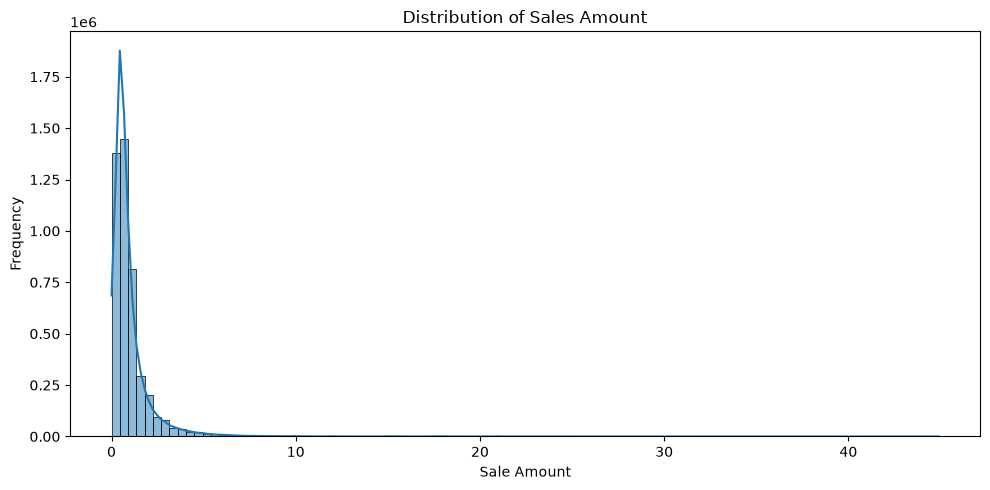

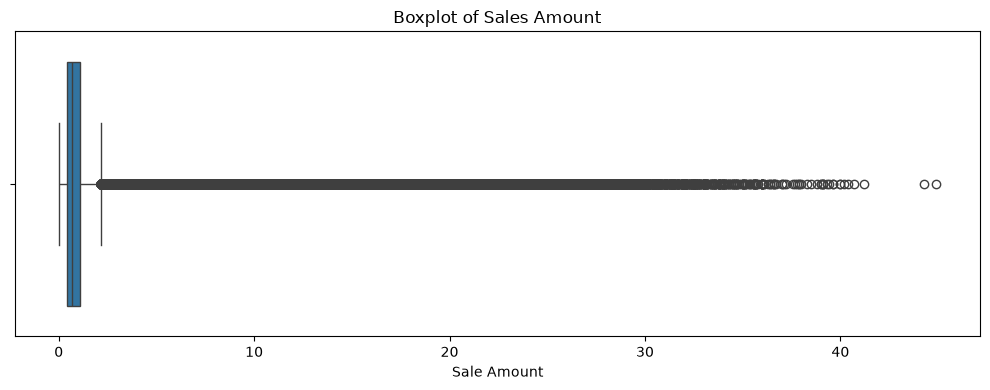

Zero-sales records: 4.46%


In [24]:
import matplotlib.pyplot as plt
import seaborn as sns

# Distribution of sales
plt.figure(figsize=(10, 5))
sns.histplot(cleaned_df["sale_amount"], bins=100, kde=True)
plt.title("Distribution of Sales Amount")
plt.xlabel("Sale Amount")
plt.ylabel("Frequency")
plt.tight_layout()
plt.show()

# Boxplot to identify extreme sales values
plt.figure(figsize=(10, 4))
sns.boxplot(x=cleaned_df["sale_amount"])
plt.title("Boxplot of Sales Amount")
plt.xlabel("Sale Amount")
plt.tight_layout()
plt.show()

# Percentage of zero-sales records
zero_sales_percentage = (
    (cleaned_df["sale_amount"] == 0).mean() * 100
)

print(f"Zero-sales records: {zero_sales_percentage:.2f}%")

**Interpretation of Sales Distribution**

The histogram and boxplot show that the `sale_amount` variable is strongly positively skewed (right-skewed).

- Most observations are concentrated around relatively low sales values.
- A long right tail indicates that a small proportion of observations have substantially higher sales.
- The boxplot identifies numerous potential upper-end outliers.
- The mean sales amount (approximately 0.999) is higher than the median (0.7), further indicating positive skewness.

**Impact on Machine Learning Models**

This skewed distribution may affect model performance. In particular, regression models that are sensitive to extreme values may be influenced disproportionately by observations with very high sales.

**Planned Treatment**

We will not remove high-sales observations automatically because they may represent genuine sales activity.

Instead, we will:

1. Investigate extreme values to distinguish genuine high-sales observations from possible data errors.
2. Consider a logarithmic transformation using `log1p(sale_amount)` to reduce skewness.
3. Compare model performance with and without the transformation.
4. Evaluate final predictions on the original sales scale using appropriate regression metrics such as MAE, RMSE and WAPE.

The transformation will only be retained if it improves validation performance. The original `sale_amount` values will be preserved for interpretation and evaluation.

In [25]:
print("Sales skewness:", cleaned_df["sale_amount"].skew())

zero_sales_percentage = (
    (cleaned_df["sale_amount"] == 0).mean() * 100
)

print(f"Zero-sales records: {zero_sales_percentage:.2f}%")

Sales skewness: 8.471775179820984
Zero-sales records: 4.46%


**Additional Statistical Findings**

The calculated sales skewness is 8.47, confirming a strongly right-skewed distribution. Approximately 4.46% of records have zero sales. This indicates that zero-sales observations are present but do not dominate the dataset. The skewness will be considered during feature preparation and model development, with logarithmic transformation evaluated as an experimental approach rather than applied automatically.

### 4.3 Sales Trends Over Time

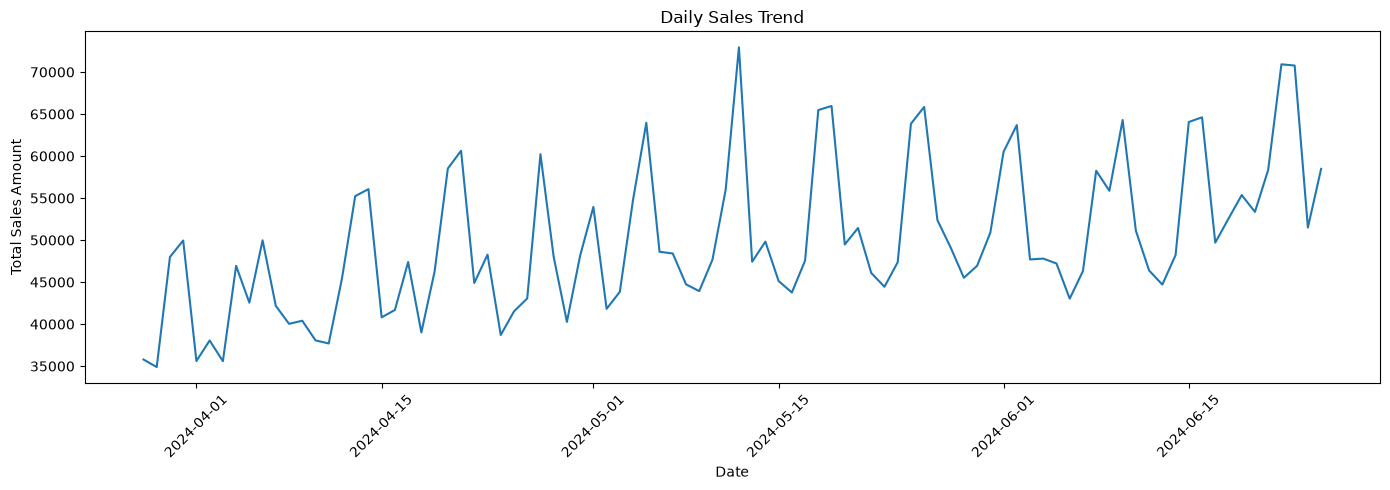

Number of dates: 90
Average daily sales: 49929.5643
Minimum daily sales: 34893.476
Maximum daily sales: 72938.825


In [26]:
# Aggregate sales by date
daily_sales = (
    cleaned_df.groupby("dt")["sale_amount"]
    .sum()
    .reset_index()
)

plt.figure(figsize=(14, 5))
sns.lineplot(data=daily_sales, x="dt", y="sale_amount")

plt.title("Daily Sales Trend")
plt.xlabel("Date")
plt.ylabel("Total Sales Amount")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

# Summary statistics
print("Number of dates:", daily_sales["dt"].nunique())
print("Average daily sales:", daily_sales["sale_amount"].mean())
print("Minimum daily sales:", daily_sales["sale_amount"].min())
print("Maximum daily sales:", daily_sales["sale_amount"].max())

**Interpretation of Daily Sales Trends**

The daily sales trend shows noticeable fluctuations throughout the 90-day observation period.

- Daily sales vary considerably, with a minimum of approximately 34,893 and a maximum of approximately 72,939.
- Several recurring peaks and declines are visible, suggesting possible weekly or other periodic sales patterns.
- Overall sales show some variation over time, but the graph alone does not establish a consistent upward or downward trend.
- These fluctuations may be associated with holidays, promotional activities, discounts, product availability, or other factors.

**Relevance to the Machine Learning Approach**

Although this project does not use traditional time-series forecasting methods, temporal patterns remain important. We will use date-based features and appropriately constructed historical sales features in supervised ML models.

A chronological data split will also be used to prevent future observations from leaking into model training.

### 4.4 Sales Analysis by Store and Product

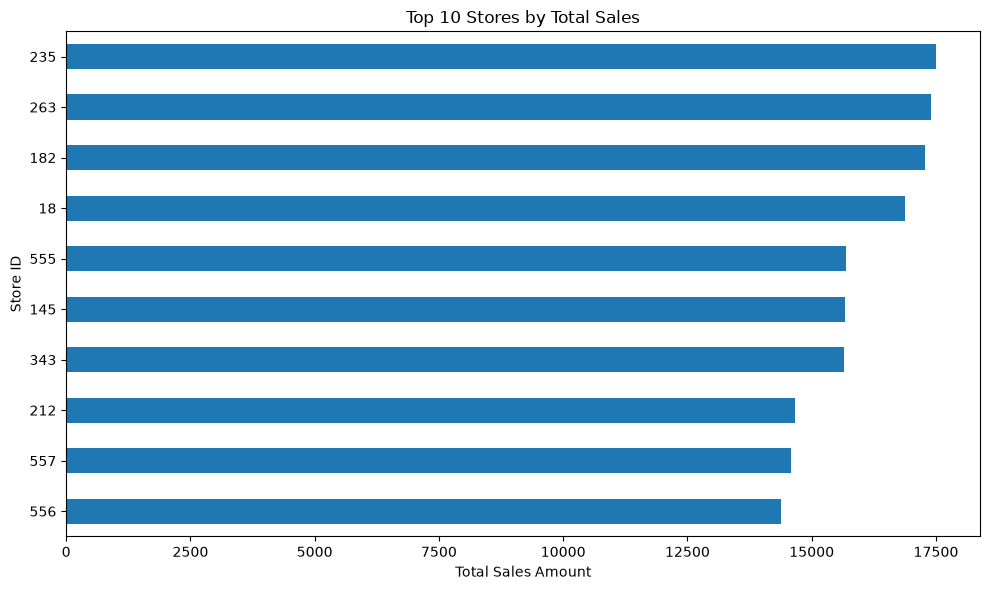

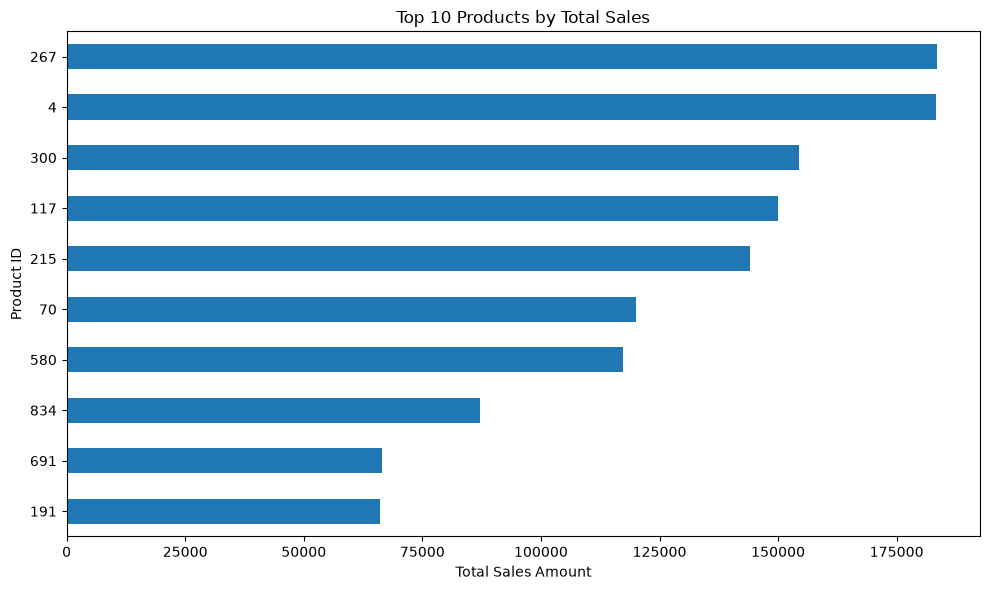

Number of stores: 898
Number of products: 865

Top 5 stores:
store_id
235    17510.530
263    17407.810
182    17269.840
18     16878.290
555    15693.479
Name: sale_amount, dtype: float64

Top 5 products:
product_id
267    183395.100
4      183265.300
300    154505.577
117    150032.945
215    144031.118
Name: sale_amount, dtype: float64


In [28]:
# Aggregate sales by store
store_sales = (
    cleaned_df.groupby("store_id")["sale_amount"]
    .sum()
    .sort_values(ascending=False)
)

# Aggregate sales by product
product_sales = (
    cleaned_df.groupby("product_id")["sale_amount"]
    .sum()
    .sort_values(ascending=False)
)

# Top 10 stores - Horizontal Bar Chart
plt.figure(figsize=(10, 6))
store_sales.head(10).sort_values().plot(kind="barh")

plt.title("Top 10 Stores by Total Sales")
plt.xlabel("Total Sales Amount")
plt.ylabel("Store ID")
plt.tight_layout()
plt.show()


# Top 10 products - Horizontal Bar Chart
plt.figure(figsize=(10, 6))
product_sales.head(10).sort_values().plot(kind="barh")

plt.title("Top 10 Products by Total Sales")
plt.xlabel("Total Sales Amount")
plt.ylabel("Product ID")
plt.tight_layout()
plt.show()

print("Number of stores:", len(store_sales))
print("Number of products:", len(product_sales))

print("\nTop 5 stores:")
print(store_sales.head())

print("\nTop 5 products:")
print(product_sales.head())

### 4.5 Sales Analysis by Category

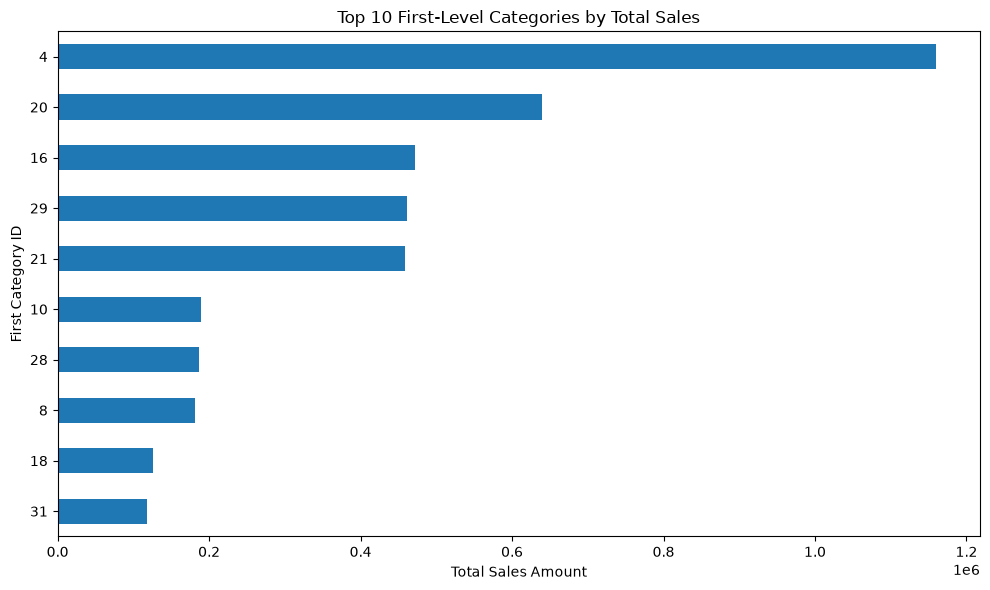

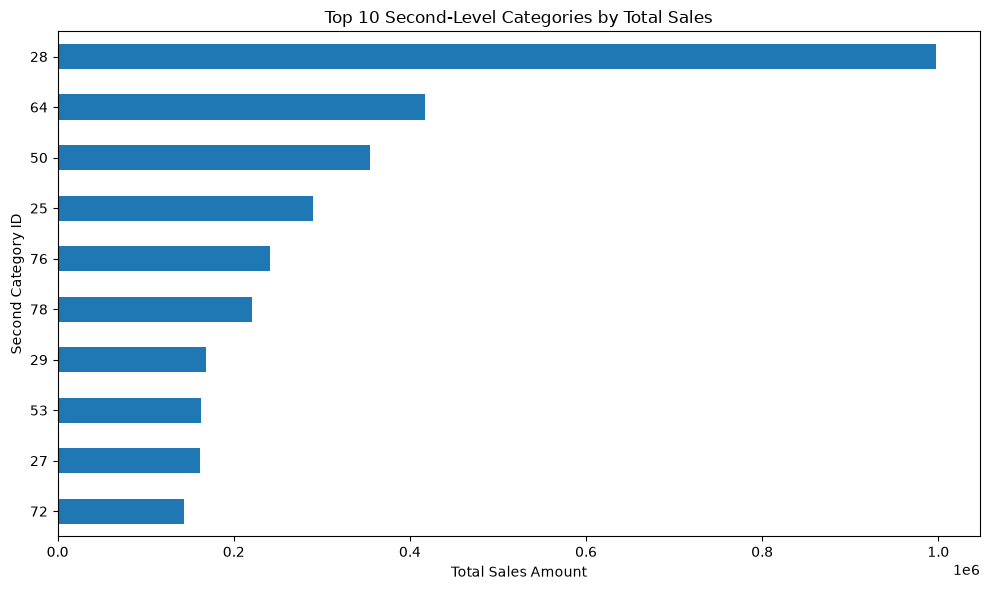

Number of first-level categories: 32
Number of second-level categories: 84
Number of third-level categories: 233

Top 5 first-level categories:
first_category_id
4     1159854.288
20     639484.020
16     472320.130
29     461595.600
21     459301.910
Name: sale_amount, dtype: float64

Top 5 second-level categories:
second_category_id
28    997477.088
64    416849.410
50    354995.975
25    289463.350
76    240606.100
Name: sale_amount, dtype: float64


In [29]:
# Aggregate sales by category levels
first_category_sales = (
    cleaned_df.groupby("first_category_id")["sale_amount"]
    .sum()
    .sort_values(ascending=False)
)

second_category_sales = (
    cleaned_df.groupby("second_category_id")["sale_amount"]
    .sum()
    .sort_values(ascending=False)
)

third_category_sales = (
    cleaned_df.groupby("third_category_id")["sale_amount"]
    .sum()
    .sort_values(ascending=False)
)

# Top 10 first-level categories
plt.figure(figsize=(10, 6))
first_category_sales.head(10).sort_values().plot(kind="barh")
plt.title("Top 10 First-Level Categories by Total Sales")
plt.xlabel("Total Sales Amount")
plt.ylabel("First Category ID")
plt.tight_layout()
plt.show()

# Top 10 second-level categories
plt.figure(figsize=(10, 6))
second_category_sales.head(10).sort_values().plot(kind="barh")
plt.title("Top 10 Second-Level Categories by Total Sales")
plt.xlabel("Total Sales Amount")
plt.ylabel("Second Category ID")
plt.tight_layout()
plt.show()

print("Number of first-level categories:", len(first_category_sales))
print("Number of second-level categories:", len(second_category_sales))
print("Number of third-level categories:", cleaned_df["third_category_id"].nunique())

print("\nTop 5 first-level categories:")
print(first_category_sales.head())

print("\nTop 5 second-level categories:")
print(second_category_sales.head())

**Interpretation of Sales by Category**

The category-level analysis reveals an uneven distribution of sales across product categories.

- The dataset contains 32 first-level categories, 84 second-level categories, and 233 third-level categories.
- First-level category 4 has the highest total sales, contributing approximately 1.16 million in sales amount.
- First-level category 20 ranks second, with approximately 639,484.
- Second-level category 28 has the highest total sales, contributing approximately 997,477.
- The difference between the highest-ranking categories and the remaining categories indicates that sales are concentrated in certain product groups.

**Relevance to Machine Learning**

Category identifiers may help capture differences in sales behaviour across product groups. We will consider these variables as categorical features during model development rather than treating their numerical IDs as continuous measurements.

### 4.6 Sales Analysis by City

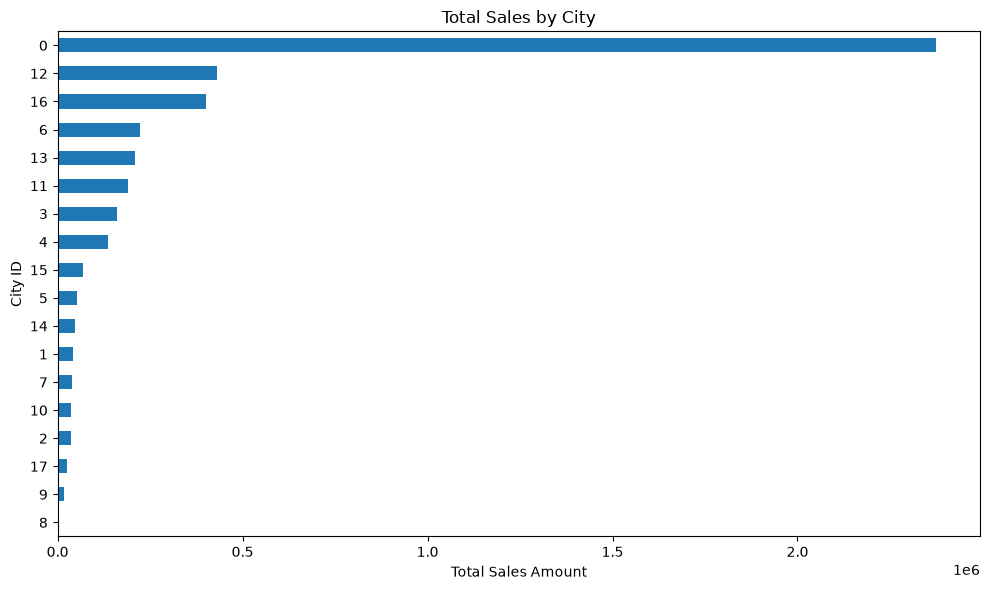

Number of cities: 18

Sales by city:
city_id
0     2374623.838
12     429614.580
16     402280.885
6      221633.112
13     209188.069
11     190952.319
3      161878.525
4      136821.517
15      68081.183
5       53397.982
14      46798.336
1       41083.772
7       37881.394
10      37175.080
2       35375.672
17      25690.660
9       16560.900
8        4622.963
Name: sale_amount, dtype: float64

Top 5 cities:
city_id
0     2374623.838
12     429614.580
16     402280.885
6      221633.112
13     209188.069
Name: sale_amount, dtype: float64


In [30]:
# Aggregate sales by city
city_sales = (
    cleaned_df.groupby("city_id")["sale_amount"]
    .sum()
    .sort_values(ascending=False)
)

# Horizontal bar chart
plt.figure(figsize=(10, 6))
city_sales.sort_values().plot(kind="barh")

plt.title("Total Sales by City")
plt.xlabel("Total Sales Amount")
plt.ylabel("City ID")
plt.tight_layout()
plt.show()

print("Number of cities:", len(city_sales))

print("\nSales by city:")
print(city_sales)

print("\nTop 5 cities:")
print(city_sales.head())

**Interpretation of Sales by City**

The city-level analysis shows an uneven distribution of total sales across the 18 cities.

- City 0 has the highest total sales, approximately 2.37 million, substantially exceeding all other cities.
- Cities 12 and 16 are the next highest contributors, with approximately 429,615 and 402,281 in total sales, respectively.
- The remaining cities contribute considerably smaller sales amounts.
- This indicates that overall sales are concentrated in a few cities rather than being evenly distributed geographically.

**Relevance to Machine Learning**

City identifiers may capture geographical differences in sales behaviour. We will consider `city_id` as a categorical feature during model development. We should also investigate whether the sales differences reflect different numbers of stores or products across cities.

### 4.7 Sales Analysis by Discounts

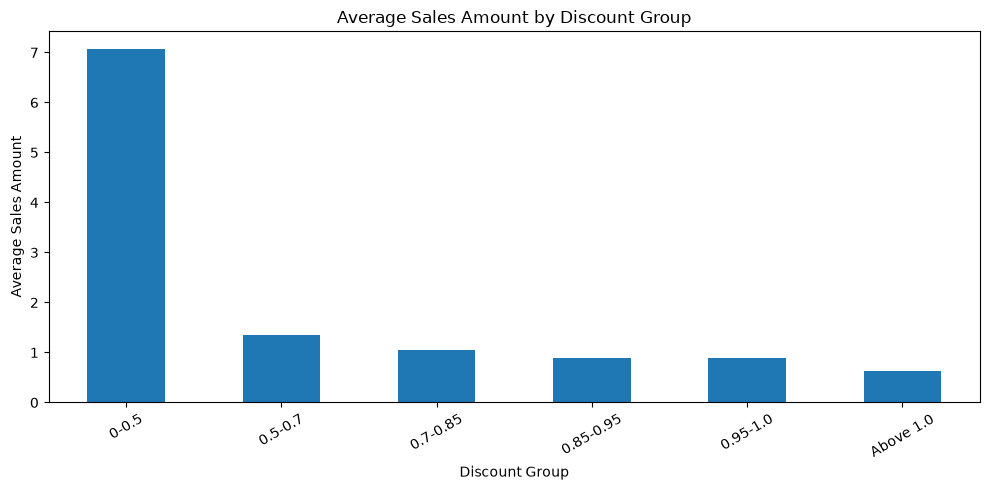

Average sales by discount group:
discount_group
0-0.5        7.068720
0.5-0.7      1.353993
0.7-0.85     1.043875
0.85-0.95    0.886678
0.95-1.0     0.887425
Above 1.0    0.635294
Name: sale_amount, dtype: float64

Discount value distribution:
count    4.500000e+06
mean     9.111412e-01
std      1.281734e-01
min      0.000000e+00
25%      8.510000e-01
50%      9.890000e-01
75%      1.000000e+00
max      1.088000e+00
Name: discount, dtype: float64


In [31]:
# Create discount ranges for exploratory analysis
cleaned_df["discount_group"] = pd.cut(
    cleaned_df["discount"],
    bins=[-0.001, 0.5, 0.7, 0.85, 0.95, 1.0, float("inf")],
    labels=[
        "0-0.5",
        "0.5-0.7",
        "0.7-0.85",
        "0.85-0.95",
        "0.95-1.0",
        "Above 1.0"
    ]
)

discount_sales = (
    cleaned_df.groupby("discount_group", observed=False)["sale_amount"]
    .mean()
)

plt.figure(figsize=(10, 5))
discount_sales.plot(kind="bar")
plt.title("Average Sales Amount by Discount Group")
plt.xlabel("Discount Group")
plt.ylabel("Average Sales Amount")
plt.xticks(rotation=30)
plt.tight_layout()
plt.show()

print("Average sales by discount group:")
print(discount_sales)

print("\nDiscount value distribution:")
print(cleaned_df["discount"].describe())

**Interpretation of Sales by Discounts**

The analysis compares average sales amounts across six discount groups.

- The 0–0.5 discount group has the highest average sales amount (approximately 7.07).
- The 0.5–0.7 group has an average sales amount of approximately 1.35.
- Average sales generally decrease across the higher discount groups.
- The above-1.0 group has the lowest average sales amount, approximately 0.64.
- Most discount observations are concentrated near 1.0, as indicated by the median of 0.989.

**Key Observation**

The results do not show a positive relationship between higher discount values and higher average sales. However, this is an observational comparison and does not establish that discounts reduce sales. Differences in products, stores, promotions, and other factors may influence the results.

**Relevance to Machine Learning**

The discount variable will be retained as a potential predictor. Its relationship with sales will be examined alongside other features during model development. Values above 1.0 will also be investigated before deciding whether any treatment is necessary.

### 4.8 Sales Analysis by Holiday and Activity

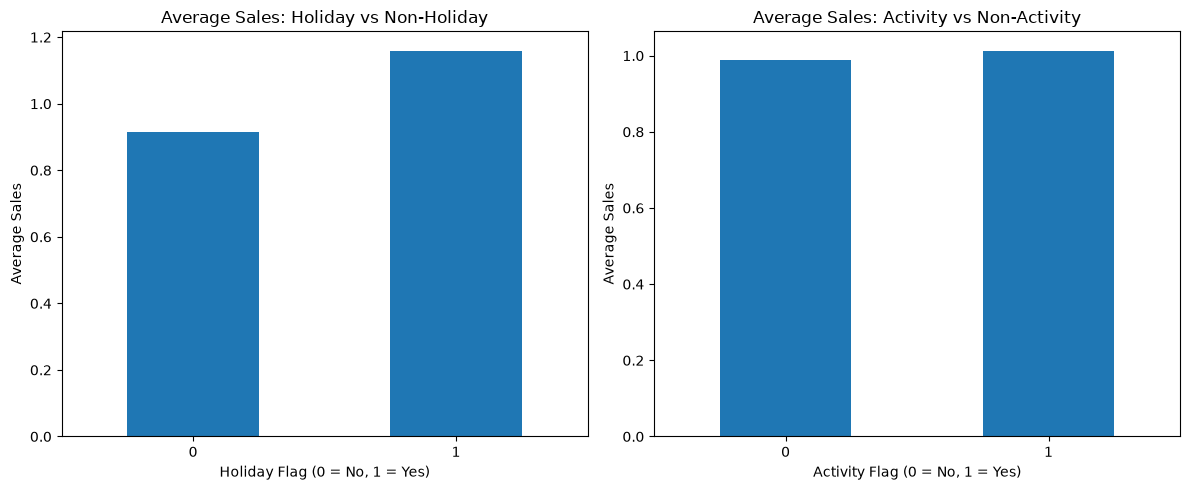

Average sales by holiday status:
holiday_flag
0    0.913969
1    1.159647
Name: sale_amount, dtype: float64

Average sales by activity status:
activity_flag
0    0.989662
1    1.013258
Name: sale_amount, dtype: float64


In [32]:
# Average sales by holiday status
holiday_sales = cleaned_df.groupby("holiday_flag")["sale_amount"].mean()

# Average sales by activity status
activity_sales = cleaned_df.groupby("activity_flag")["sale_amount"].mean()

# Plot comparisons
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

holiday_sales.plot(kind="bar", ax=axes[0])
axes[0].set_title("Average Sales: Holiday vs Non-Holiday")
axes[0].set_xlabel("Holiday Flag (0 = No, 1 = Yes)")
axes[0].set_ylabel("Average Sales")
axes[0].tick_params(axis="x", rotation=0)

activity_sales.plot(kind="bar", ax=axes[1])
axes[1].set_title("Average Sales: Activity vs Non-Activity")
axes[1].set_xlabel("Activity Flag (0 = No, 1 = Yes)")
axes[1].set_ylabel("Average Sales")
axes[1].tick_params(axis="x", rotation=0)

plt.tight_layout()
plt.show()

print("Average sales by holiday status:")
print(holiday_sales)

print("\nAverage sales by activity status:")
print(activity_sales)

**Interpretation of Sales by Holiday and Activity**

The analysis compares average sales across holiday and activity conditions.

- **Holiday effect:** Average sales on holidays (approximately 1.16) are higher than on non-holidays (approximately 0.91).
- **Activity effect:** Average sales on active days (approximately 1.01) are slightly higher than on non-active days (approximately 0.99).
- The difference associated with holidays is more noticeable than the difference associated with activity status.

**Key Observation**

Holiday periods appear to be associated with higher average sales, while activity status shows a relatively small difference.

These results indicate potential relationships, but they do not establish causation. Other factors, including product mix, store characteristics, discounts, and stock availability, may influence sales.

**Relevance to Machine Learning**

Both `holiday_flag` and `activity_flag` will be considered as potential predictive features in the supervised learning models.

### 4.9 Weather Impact on Sales

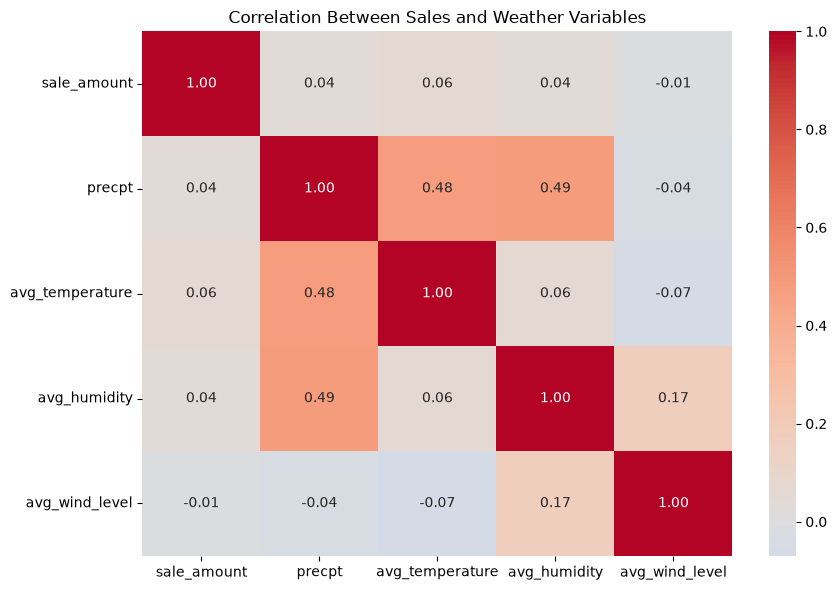

Correlation of weather variables with sales:
avg_wind_level    -0.007699
precpt             0.037044
avg_humidity       0.043337
avg_temperature    0.056425
Name: sale_amount, dtype: float64


In [33]:
# Correlation between weather variables and sales
weather_columns = [
    "sale_amount",
    "precpt",
    "avg_temperature",
    "avg_humidity",
    "avg_wind_level"
]

weather_corr = cleaned_df[weather_columns].corr()

plt.figure(figsize=(9, 6))
sns.heatmap(
    weather_corr,
    annot=True,
    cmap="coolwarm",
    fmt=".2f",
    center=0
)

plt.title("Correlation Between Sales and Weather Variables")
plt.tight_layout()
plt.show()

print("Correlation of weather variables with sales:")
print(weather_corr["sale_amount"].drop("sale_amount").sort_values())

**Interpretation of Weather Impact on Sales**

The correlation analysis examines the linear relationships between sales and four weather variables.

- **Temperature:** Shows a weak positive correlation with sales (0.056).
- **Humidity:** Shows a weak positive correlation (0.043).
- **Precipitation:** Shows a weak positive correlation (0.037).
- **Wind level:** Shows a negligible negative correlation (-0.008).

The correlations indicate that none of the individual weather variables has a strong linear relationship with sales in this dataset.

**Additional Observation**

Precipitation has moderate positive correlations with temperature (0.48) and humidity (0.49). This suggests some relationships among the weather predictors themselves.

**Relevance to Machine Learning**

Weather variables will be retained as potential predictive features for initial model experiments. Although their individual linear correlations with sales are weak, they may still provide useful information through nonlinear relationships or interactions with other variables.

Correlation alone is not sufficient to determine feature importance or predictive usefulness.

### 4.10 Correlation Analysis of Numerical Features

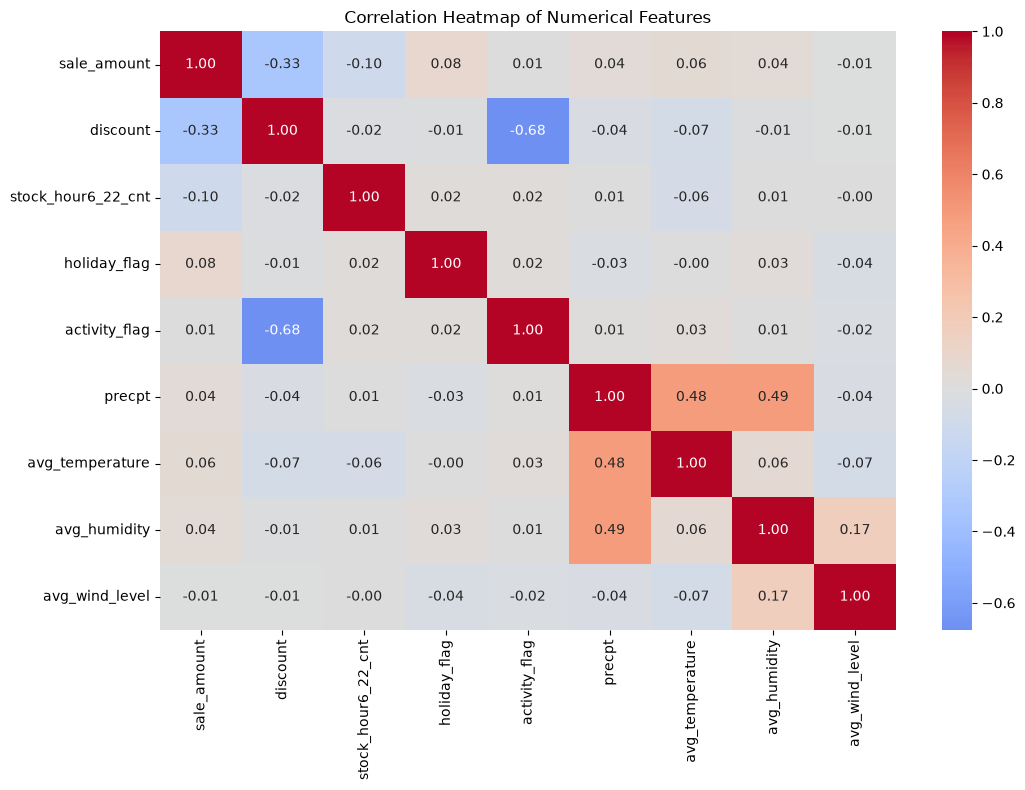

Correlations with sale_amount:
discount             -0.332888
stock_hour6_22_cnt   -0.100773
avg_wind_level       -0.007699
activity_flag         0.008135
precpt                0.037044
avg_humidity          0.043337
avg_temperature       0.056425
holiday_flag          0.082988
Name: sale_amount, dtype: float64


In [34]:
# Select numerical columns, excluding identifier variables
correlation_columns = [
    "sale_amount",
    "discount",
    "stock_hour6_22_cnt",
    "holiday_flag",
    "activity_flag",
    "precpt",
    "avg_temperature",
    "avg_humidity",
    "avg_wind_level"
]

correlation_matrix = cleaned_df[correlation_columns].corr()

plt.figure(figsize=(11, 8))
sns.heatmap(
    correlation_matrix,
    annot=True,
    cmap="coolwarm",
    fmt=".2f",
    center=0
)

plt.title("Correlation Heatmap of Numerical Features")
plt.tight_layout()
plt.show()

print("Correlations with sale_amount:")
print(
    correlation_matrix["sale_amount"]
    .drop("sale_amount")
    .sort_values()
)

**Interpretation of Correlation Analysis**

The correlation heatmap highlights the linear relationships between sales and the numerical predictor variables.

- Discount has the strongest relationship with sales, with a negative correlation of approximately -0.33.
- Stock count has a weak negative correlation with sales (-0.10).
- Holiday status has a weak positive correlation with sales (0.08).
- Weather variables and activity status have relatively weak individual correlations with sales.
- A strong negative correlation (-0.68) exists between discount and activity status, suggesting a potential relationship between promotional activity and discount levels.

**Implications for Feature Selection**

The observed correlations suggest that discount and stock-related variables may provide useful predictive information. However, correlation alone does not determine whether a feature should be retained or removed.

We will initially retain relevant features and assess their predictive contributions during model development. Potential multicollinearity will also be considered when selecting and comparing models.

### 4.11 EDA Summary and Key Findings

**Exploratory Data Analysis Summary**

The exploratory data analysis was performed to understand sales behaviour, product and store distributions, geographical differences, promotional patterns, and relationships between numerical variables.

**Major Findings**

1. **Sales Distribution:** Sales are strongly right-skewed, with a skewness of 8.47. Approximately 4.46% of records have zero sales.
2. **Temporal Patterns:** Daily sales fluctuate throughout the 90-day observation period, with noticeable peaks and declines.
3. **Store and Product Performance:** Sales contributions vary across 898 stores and 865 products.
4. **Category Distribution:** Sales are concentrated in certain first-level and second-level product categories.
5. **Geographical Distribution:** City-level sales vary considerably, with City 0 contributing the highest total sales.
6. **Discount Patterns:** Higher discount groups show lower average sales in the exploratory comparison. This relationship requires further investigation.
7. **Holiday and Activity Effects:** Average sales are higher on holidays, while activity status shows a relatively small difference.
8. **Weather Relationships:** Weather variables have weak individual linear correlations with sales.
9. **Feature Correlations:** Discount has a moderate negative correlation with sales (-0.33), while discount and activity status have a strong negative correlation (-0.68).

**Conclusion**

The EDA identifies several potentially useful predictors, including product and store identifiers, category information, discount, stock-related variables, holiday status, activity status, and weather measurements.

These findings will guide feature engineering and supervised machine learning model development. No observations will be removed solely because they appear as statistical outliers. Further feature validation and selection will be performed during preprocessing and model evaluation.

## 5. Data Transformation and Feature Engineering

### 5.1 Feature and Target Investigation

In [36]:
import ast
import numpy as np

# Examine a sample of 1,000 records
sample = cleaned_df.sample(n=1000, random_state=42).copy()

# Parse hourly sales and calculate their daily totals
sample["hourly_sales_total"] = sample["hours_sale"].apply(
    lambda x: sum(ast.literal_eval(x))
)

# Parse hourly stock status and calculate the number of active hours
sample["hourly_stock_status_total"] = sample["hours_stock_status"].apply(
    lambda x: sum(ast.literal_eval(x))
)

# Compare hourly sales totals with daily sales amounts
sample["sales_difference"] = (
    sample["sale_amount"] - sample["hourly_sales_total"]
)

print("Hourly sales total vs daily sale_amount:")
print(sample[["sale_amount", "hourly_sales_total"]].head(10))

print("\nMean absolute difference:")
print(sample["sales_difference"].abs().mean())

print("\nMaximum absolute difference:")
print(sample["sales_difference"].abs().max())

# Investigate stock-related columns
print("\nStock-related columns:")
print(
    sample[
        ["stock_hour6_22_cnt", "hourly_stock_status_total"]
    ].head(10)
)

print("\nCorrelation between stock-related counts:")
print(
    sample[
        ["stock_hour6_22_cnt", "hourly_stock_status_total"]
    ].corr()
)


Hourly sales total vs daily sale_amount:
         sale_amount  hourly_sales_total
2688763          0.7                 0.7
491106           1.7                 1.7
1774899          1.6                 1.6
1272686          1.1                 1.1
4332815          1.3                 1.3
2244304          0.5                 0.5
758270           3.0                 3.0
2716032          0.8                 0.8
3948794          2.7                 2.7
2408377          0.1                 0.1

Mean absolute difference:
3.216871213851391e-17

Maximum absolute difference:
8.881784197001252e-16

Stock-related columns:
         stock_hour6_22_cnt  hourly_stock_status_total
2688763                   4                          9
491106                    9                         12
1774899                   5                         12
1272686                   0                          0
4332815                   0                          0
2244304                   0                          

In [37]:
# Investigate the relationship between hourly stock status
# and stock_hour6_22_cnt

stock_sample = cleaned_df.sample(n=1000, random_state=42).copy()

stock_sample["hourly_status"] = stock_sample[
    "hours_stock_status"
].apply(ast.literal_eval)

# Sum status entries from hour 6 through hour 22 (inclusive)
stock_sample["calculated_stock_count"] = stock_sample[
    "hourly_status"
].apply(lambda x: sum(x[6:23]))

print("Original vs calculated stock counts:")
display(
    stock_sample[
        ["stock_hour6_22_cnt", "calculated_stock_count"]
    ].head(15)
)

print(
    "\nNumber of exact matches:",
    (
        stock_sample["stock_hour6_22_cnt"]
        == stock_sample["calculated_stock_count"]
    ).sum(),
    "out of", len(stock_sample)
)

print("\nHourly stock-status values:")
print(
    stock_sample["hourly_status"]
    .explode()
    .value_counts()
    .sort_index()
)


Original vs calculated stock counts:


,stock_hour6_22_cnt,calculated_stock_count
2688763,4,5
491106,9,10
1774899,5,6
1272686,0,0
4332815,0,0
2244304,0,0
758270,5,6
2716032,0,0
3948794,0,0
2408377,0,0



Number of exact matches: 611 out of 1000

Hourly stock-status values:
hourly_status
0    18427
1     5573
Name: count, dtype: int64


In [ ]:
# Compare possible hourly ranges against the original stock count

stock_sample["count_6_to_21"] = stock_sample[
    "hourly_status"
].apply(lambda x: sum(x[6:22]))

stock_sample["count_7_to_22"] = stock_sample[
    "hourly_status"
].apply(lambda x: sum(x[7:23]))

print("Matches using hours 6–21:",
    (stock_sample["stock_hour6_22_cnt"]
    == stock_sample["count_6_to_21"]).sum())

print("Matches using hours 7–22:",
    (stock_sample["stock_hour6_22_cnt"]
    == stock_sample["count_7_to_22"]).sum())


Matches using hours 6–21: 1000
Matches using hours 7–22: 652


### 5.2 Feature Selection and Preparation

In [39]:

# Select relevant columns for supervised learning

selected_features = [
    "city_id",
    "store_id",
    "management_group_id",
    "first_category_id",
    "second_category_id",
    "third_category_id",
    "product_id",
    "dt",
    "discount",
    "stock_hour6_22_cnt",
    "holiday_flag",
    "activity_flag",
    "precpt",
    "avg_temperature",
    "avg_humidity",
    "avg_wind_level"
]

target_column = "sale_amount"

# Create modeling dataset
model_df = cleaned_df[selected_features + [target_column]].copy()

# Remove raw hourly list columns and any EDA-only columns
print("Modeling dataset shape:", model_df.shape)

print("\nSelected features:")
print(selected_features)

print("\nTarget variable:", target_column)

print("\nMissing values:")
print(model_df.isnull().sum().sum())

print("\nData types:")
print(model_df.dtypes)


Modeling dataset shape: (4500000, 17)

Selected features:
['city_id', 'store_id', 'management_group_id', 'first_category_id', 'second_category_id', 'third_category_id', 'product_id', 'dt', 'discount', 'stock_hour6_22_cnt', 'holiday_flag', 'activity_flag', 'precpt', 'avg_temperature', 'avg_humidity', 'avg_wind_level']

Target variable: sale_amount

Missing values:
0

Data types:
city_id                         int64
store_id                        int64
management_group_id             int64
first_category_id               int64
second_category_id              int64
third_category_id               int64
product_id                      int64
dt                     datetime64[us]
discount                      float64
stock_hour6_22_cnt              int64
holiday_flag                    int64
activity_flag                   int64
precpt                        float64
avg_temperature               float64
avg_humidity                  float64
avg_wind_level                float64
sale_amount

### 5.3 Date-Based Feature Engineering

In [ ]:
# Extract calendar-based features

model_df["day_of_week"] = model_df["dt"].dt.dayofweek
model_df["day_of_month"] = model_df["dt"].dt.day
model_df["month"] = model_df["dt"].dt.month
model_df["week_of_year"] = (
    model_df["dt"].dt.isocalendar().week.astype(int)
)
model_df["is_weekend"] = (
    model_df["day_of_week"].isin([5, 6]).astype(int)
)

# Display the newly created features
date_features = [
    "dt",
    "day_of_week",
    "day_of_month",
    "month",
    "week_of_year",
    "is_weekend"
]

display(model_df[date_features].head(10))

print("\nDate feature summary:")
display(model_df[date_features[1:]].describe())


,dt,day_of_week,day_of_month,month,week_of_year,is_weekend
0,2024-03-28,3,28,3,13,0
1,2024-03-29,4,29,3,13,0
2,2024-03-30,5,30,3,13,1
3,2024-03-31,6,31,3,13,1
4,2024-04-01,0,1,4,14,0
5,2024-04-02,1,2,4,14,0
6,2024-04-03,2,3,4,14,0
7,2024-04-04,3,4,4,14,0
8,2024-04-05,4,5,4,14,0
9,2024-04-06,5,6,4,14,1



Date feature summary:


,day_of_week,day_of_month,month,week_of_year,is_weekend
count,4.500000e+06,4.500000e+06,4.500000e+06,4.500000e+06,4.500000e+06
mean,3.011111e+00,1.560000e+01,4.855556e+00,1.935556e+01,2.888889e-01
std,2.008286e+00,8.806312e+00,8.763703e-01,3.730687e+00,4.532462e-01
min,0.000000e+00,1.000000e+00,3.000000e+00,1.300000e+01,0.000000e+00
25%,1.000000e+00,8.000000e+00,4.000000e+00,1.600000e+01,0.000000e+00
50%,3.000000e+00,1.550000e+01,5.000000e+00,1.900000e+01,0.000000e+00
75%,5.000000e+00,2.300000e+01,6.000000e+00,2.300000e+01,1.000000e+00
max,6.000000e+00,3.100000e+01,6.000000e+00,2.600000e+01,1.000000e+00


### 5.4 Historical Sales Feature Engineering

In [41]:

# Sort records chronologically within each store-product series
model_df = model_df.sort_values(
    ["store_id", "product_id", "dt"]
).copy()

# Create historical sales features
grouped_sales = model_df.groupby(
    ["store_id", "product_id"]
)["sale_amount"]

model_df["sales_lag_1"] = grouped_sales.shift(1)
model_df["sales_lag_7"] = grouped_sales.shift(7)

# Display sample records
display(
    model_df[
        ["store_id", "product_id", "dt", "sale_amount",
        "sales_lag_1", "sales_lag_7"]
    ].head(20)
)

print("Missing values in lag features:")
print(model_df[["sales_lag_1", "sales_lag_7"]].isnull().sum())

print("\nLag feature summary:")
display(model_df[["sales_lag_1", "sales_lag_7"]].describe())


,store_id,product_id,dt,sale_amount,sales_lag_1,sales_lag_7
720,0,4,2024-03-28,0.5,NaN,NaN
721,0,4,2024-03-29,1.3,0.5,NaN
722,0,4,2024-03-30,5.3,1.3,NaN
723,0,4,2024-03-31,4.2,5.3,NaN
724,0,4,2024-04-01,0.7,4.2,NaN
725,0,4,2024-04-02,2.3,0.7,NaN
726,0,4,2024-04-03,1.3,2.3,NaN
727,0,4,2024-04-04,4.7,1.3,0.5
728,0,4,2024-04-05,3.1,4.7,1.3
729,0,4,2024-04-06,5.5,3.1,5.3


Missing values in lag features:
sales_lag_1     50000
sales_lag_7    350000
dtype: int64

Lag feature summary:


,sales_lag_1,sales_lag_7
count,4.450000e+06,4.150000e+06
mean,9.966713e-01,9.819119e-01
std,1.400388e+00,1.361652e+00
min,0.000000e+00,0.000000e+00
25%,4.000000e-01,4.000000e-01
50%,7.000000e-01,7.000000e-01
75%,1.100000e+00,1.100000e+00
max,4.490000e+01,4.020000e+01


In [ ]:
# Check whether consecutive observations are one calendar day apart
model_df["previous_date"] = (
    model_df.groupby(["store_id", "product_id"])["dt"].shift(1)
)

model_df["days_between_records"] = (
    model_df["dt"] - model_df["previous_date"]
).dt.days

print("Days between consecutive observations:")
display(model_df["days_between_records"].value_counts().sort_index())

print("\nPercentage of consecutive observations exactly 1 day apart:")
valid_gaps = model_df["days_between_records"].dropna()

print(
    f"{(valid_gaps == 1).mean() * 100:.2f}%"
)

print("\nNumber of gaps greater than 1 day:")
print((valid_gaps > 1).sum())


Days between consecutive observations:


days_between_records
1.0    4450000
Name: count, dtype: int64


Percentage of consecutive observations exactly 1 day apart:
100.00%

Number of gaps greater than 1 day:
0


In [ ]:
# Verify lag values against historical sales
sample = model_df[
    model_df["sales_lag_7"].notna()
].sample(1000, random_state=42)

# Reconstruct expected historical values
expected_lag_1 = (
    model_df.groupby(["store_id", "product_id"])["sale_amount"]
    .shift(1)
    .loc[sample.index]
)

expected_lag_7 = (
    model_df.groupby(["store_id", "product_id"])["sale_amount"]
    .shift(7)
    .loc[sample.index]
)

print(
    "Lag 1 matches:",
    (sample["sales_lag_1"] == expected_lag_1).all()
)

print(
    "Lag 7 matches:",
    (sample["sales_lag_7"] == expected_lag_7).all()
)


Lag 1 matches: True
Lag 7 matches: True


In [44]:

# Define the final candidate features
final_features = [
    "city_id",
    "store_id",
    "management_group_id",
    "first_category_id",
    "second_category_id",
    "third_category_id",
    "product_id",
    "discount",
    "stock_hour6_22_cnt",
    "holiday_flag",
    "activity_flag",
    "precpt",
    "avg_temperature",
    "avg_humidity",
    "avg_wind_level",
    "day_of_week",
    "day_of_month",
    "month",
    "week_of_year",
    "is_weekend",
    "sales_lag_1",
    "sales_lag_7"
]

target_column = "sale_amount"

# Create the modeling dataset
modeling_df = model_df[final_features + [target_column]].copy()

print("Modeling dataset shape:", modeling_df.shape)

print("\nMissing values:")
display(modeling_df.isnull().sum())

print("\nDuplicate rows:", modeling_df.duplicated().sum())

print("\nFeature count:", len(final_features))
print("Target column:", target_column)

print("\nFeature data types:")
display(modeling_df.dtypes)


Modeling dataset shape: (4500000, 23)

Missing values:


city_id                     0
store_id                    0
management_group_id         0
first_category_id           0
second_category_id          0
third_category_id           0
product_id                  0
discount                    0
stock_hour6_22_cnt          0
holiday_flag                0
activity_flag               0
precpt                      0
avg_temperature             0
avg_humidity                0
avg_wind_level              0
day_of_week                 0
day_of_month                0
month                       0
week_of_year                0
is_weekend                  0
sales_lag_1             50000
sales_lag_7            350000
sale_amount                 0
dtype: int64


Duplicate rows: 0

Feature count: 22
Target column: sale_amount

Feature data types:


city_id                  int64
store_id                 int64
management_group_id      int64
first_category_id        int64
second_category_id       int64
third_category_id        int64
product_id               int64
discount               float64
stock_hour6_22_cnt       int64
holiday_flag             int64
activity_flag            int64
precpt                 float64
avg_temperature        float64
avg_humidity           float64
avg_wind_level         float64
day_of_week              int32
day_of_month             int32
month                    int32
week_of_year             int64
is_weekend               int64
sales_lag_1            float64
sales_lag_7            float64
sale_amount            float64
dtype: object

In [45]:
# Count records with complete lag history
complete_history = modeling_df[
    ["sales_lag_1", "sales_lag_7"]
].notna().all(axis=1)

print("Records with complete lag history:", complete_history.sum())
print("Records without complete lag history:", (~complete_history).sum())

print(
    "Percentage with complete history:",
    round(complete_history.mean() * 100, 2), "%"
)

# Check target availability
print("\nMissing target values:", modeling_df[target_column].isna().sum())


Records with complete lag history: 4150000
Records without complete lag history: 350000
Percentage with complete history: 92.22 %

Missing target values: 0


In [46]:

# Keep records with complete historical sales features
modeling_df = modeling_df.dropna(
    subset=["sales_lag_1", "sales_lag_7"]
).copy()

# Reset index
modeling_df.reset_index(drop=True, inplace=True)

print("Final modeling dataset shape:", modeling_df.shape)
print("\nRemaining missing values:", modeling_df.isnull().sum().sum())
print("Duplicate rows:", modeling_df.duplicated().sum())
print("Target missing values:", modeling_df["sale_amount"].isnull().sum())


Final modeling dataset shape: (4150000, 23)

Remaining missing values: 0
Duplicate rows: 0
Target missing values: 0


## 6. Training, Validation and Testing Setup

## 6.1 Determine the Date Range

In [47]:
# Rebuild the final modeling dataset with its date column
valid_history = model_df[
    ["sales_lag_1", "sales_lag_7"]
].notna().all(axis=1)

modeling_df = model_df.loc[
    valid_history,
    final_features + [target_column, "dt"]
].copy()

modeling_df = modeling_df.sort_values("dt").reset_index(drop=True)

print("Dataset shape:", modeling_df.shape)
print("Start date:", modeling_df["dt"].min())
print("End date:", modeling_df["dt"].max())
print("Unique dates:", modeling_df["dt"].nunique())


Dataset shape: (4150000, 24)
Start date: 2024-04-04 00:00:00
End date: 2024-06-25 00:00:00
Unique dates: 83


### 6.2 Define Chronological Split Dates


In [48]:
# Get sorted unique dates
unique_dates = sorted(modeling_df["dt"].unique())

n_dates = len(unique_dates)

train_end = int(n_dates * 0.70)
validation_end = int(n_dates * 0.85)

train_dates = unique_dates[:train_end]
validation_dates = unique_dates[train_end:validation_end]
test_dates = unique_dates[validation_end:]

print("Training date range:", train_dates[0], "to", train_dates[-1])
print("Validation date range:", validation_dates[0], "to", validation_dates[-1])
print("Testing date range:", test_dates[0], "to", test_dates[-1])

print("\nNumber of training dates:", len(train_dates))
print("Number of validation dates:", len(validation_dates))
print("Number of testing dates:", len(test_dates))


Training date range: 2024-04-04 00:00:00 to 2024-05-31 00:00:00
Validation date range: 2024-06-01 00:00:00 to 2024-06-12 00:00:00
Testing date range: 2024-06-13 00:00:00 to 2024-06-25 00:00:00

Number of training dates: 58
Number of validation dates: 12
Number of testing dates: 13


### 6.3 Create Training, Validation and Testing Sets

In [49]:

# Split the dataset using the selected chronological dates
train_df = modeling_df[
    modeling_df["dt"].isin(train_dates)
].copy()

validation_df = modeling_df[
    modeling_df["dt"].isin(validation_dates)
].copy()

test_df = modeling_df[
    modeling_df["dt"].isin(test_dates)
].copy()

# Separate features and target
feature_columns = final_features

X_train = train_df[feature_columns]
y_train = train_df[target_column]

X_val = validation_df[feature_columns]
y_val = validation_df[target_column]

X_test = test_df[feature_columns]
y_test = test_df[target_column]

# Display dataset sizes
print("Training set:", X_train.shape, y_train.shape)
print("Validation set:", X_val.shape, y_val.shape)
print("Testing set:", X_test.shape, y_test.shape)

print("\nTotal records:", len(X_train) + len(X_val) + len(X_test))


Training set: (2900000, 22) (2900000,)
Validation set: (600000, 22) (600000,)
Testing set: (650000, 22) (650000,)

Total records: 4150000


### 6.4 Verify Chronological Split and Data Integrity

In [ ]:
# Verify that the date ranges do not overlap
print("Training ends:", train_df["dt"].max())
print("Validation starts:", validation_df["dt"].min())
print("Validation ends:", validation_df["dt"].max())
print("Testing starts:", test_df["dt"].min())

# Verify chronological ordering
assert train_df["dt"].max() < validation_df["dt"].min()
assert validation_df["dt"].max() < test_df["dt"].min()

# Verify all records are assigned exactly once
assert len(train_df) + len(validation_df) + len(test_df) == len(modeling_df)

# Check missing values in feature sets
print("\nMissing values:")
print("Training:", X_train.isnull().sum().sum())
print("Validation:", X_val.isnull().sum().sum())
print("Testing:", X_test.isnull().sum().sum())

print("\nAll split integrity checks passed!")


Training ends: 2024-05-31 00:00:00
Validation starts: 2024-06-01 00:00:00
Validation ends: 2024-06-12 00:00:00
Testing starts: 2024-06-13 00:00:00

Missing values:
Training: 0
Validation: 0
Testing: 0

All split integrity checks passed!


In [ ]:
# Remove the potentially unavailable same-day stock feature
feature_columns = [
    col for col in final_features
    if col != "stock_hour6_22_cnt"
]

X_train = train_df[feature_columns]
X_val = validation_df[feature_columns]
X_test = test_df[feature_columns]

print("Updated feature count:", len(feature_columns))
print("Excluded feature: stock_hour6_22_cnt")
print("Training shape:", X_train.shape)
print("Validation shape:", X_val.shape)
print("Testing shape:", X_test.shape)


Updated feature count: 21
Excluded feature: stock_hour6_22_cnt
Training shape: (2900000, 21)
Validation shape: (600000, 21)
Testing shape: (650000, 21)


## 7. Baseline Model Development

### 7.1 Define Evaluation Metrics

In [52]:
import numpy as np
import pandas as pd
from sklearn.metrics import mean_absolute_error, mean_squared_error

def evaluate_regression(y_true, y_pred):
    mae = mean_absolute_error(y_true, y_pred)
    rmse = np.sqrt(mean_squared_error(y_true, y_pred))

    denominator = np.sum(np.abs(y_true))
    wape = (
        np.sum(np.abs(y_true - y_pred)) / denominator * 100
        if denominator != 0 else np.nan
    )

    return {
        "MAE": mae,
        "RMSE": rmse,
        "WAPE (%)": wape
    }

print("Evaluation metrics function defined successfully.")


Evaluation metrics function defined successfully.


### 7.2 Mean Baseline Model

In [53]:

# Predict the mean sales value from the training set
mean_prediction = y_train.mean()

mean_predictions = np.full(
    shape=len(y_val),
    fill_value=mean_prediction
)

mean_results = evaluate_regression(y_val, mean_predictions)

print("Mean baseline prediction:", mean_prediction)
print("\nValidation performance:")
display(pd.DataFrame([mean_results], index=["Mean Baseline"]))


Mean baseline prediction: 0.9796840031034484

Validation performance:


,MAE,RMSE,WAPE (%)
Mean Baseline,0.71873,1.580422,68.218385


### 7.3 Historical Baseline Model

In [54]:
# Predict current sales using the previous day's sales
historical_predictions = X_val["sales_lag_1"].to_numpy()

historical_results = evaluate_regression(
    y_val,
    historical_predictions
)

print("Validation performance:")
display(
    pd.DataFrame(
        [historical_results],
        index=["Previous Day Baseline"]
    )
)


Validation performance:


,MAE,RMSE,WAPE (%)
Previous Day Baseline,0.449438,0.781083,42.658467


### 7.4 Baseline Model Comparison

In [ ]:
# Compare baseline model performance
baseline_comparison = pd.DataFrame(
    [mean_results, historical_results],
    index=["Mean Baseline", "Previous Day Baseline"]
)

display(baseline_comparison.round(6))



,MAE,RMSE,WAPE (%)
Mean Baseline,0.718730,1.580422,68.218385
Previous Day Baseline,0.449438,0.781083,42.658467
